# 5. Offline Route Animation and Fading Robustness Evaluation

Replay the saved single-antenna (SISO) experiment, then stress-test its fixed
routes and offline subcarrier allocations using random fading. No MIMO gain,
route replanning, or online bandwidth reoptimization is introduced.


The NAIVE and JOINT videos display the **offline static-channel results**.
The fading experiment and its QoS statistics appear separately below.
Use notebook 02 to regenerate planning results after changing the experiment.


## 0. Imports and Animation Setup

In [1]:
import importlib

import matplotlib.animation as animation
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, Video, display
from matplotlib.animation import FFMpegWriter, FuncAnimation, PillowWriter
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Circle, Rectangle

import project_config

importlib.reload(project_config)

from project_config import (
    OBSTACLES,
    FINGERPRINT_PATH,
    PATH_PLANNING_RESULTS_PATH,
    DATA_DIR, FIGURES_DIR,
    ANIMATIONS_DIR,
    RANDOM_SEED,
)


In [2]:
FPS = 10
PLAYBACK_SPEED = 2.0  # Nominal simulation seconds per video second, for MP4 and GIF.

# Missing imageio-ffmpeg or an unavailable executable must still reach GIF fallback.
try:
    import imageio_ffmpeg
    plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
except (ImportError, RuntimeError, OSError):
    pass  # Matplotlib may still discover a system FFmpeg executable.

if animation.writers.is_available("ffmpeg"):
    ANIM_BACKEND, ANIM_EXT = "ffmpeg", ".mp4"
else:
    ANIM_BACKEND, ANIM_EXT = "pillow", ".gif"


def make_writer():
    if ANIM_BACKEND == "ffmpeg":
        return FFMpegWriter(fps=FPS, bitrate=2400)
    return PillowWriter(fps=FPS)


def animation_frames(time_s, fps=FPS, speed=PLAYBACK_SPEED):
    """Map uniform playback times to nearest saved samples; always include the endpoint."""
    times = np.asarray(time_s, dtype=float)
    if times.ndim != 1 or not len(times) or not np.all(np.isfinite(times)):
        raise ValueError("Animation times must be a nonempty finite vector.")
    if times[0] != 0 or np.any(np.diff(times) <= 0):
        raise ValueError("Animation times must start at zero and increase strictly.")
    if not np.isfinite(fps) or not np.isfinite(speed) or fps <= 0 or speed <= 0:
        raise ValueError("Playback fps and speed must be finite and positive.")
    display_times = np.minimum(np.arange(int(np.ceil(times[-1] * fps / speed)) + 1) * speed / fps, times[-1])
    right = np.clip(np.searchsorted(times, display_times), 0, len(times) - 1)
    left = np.maximum(right - 1, 0)
    frames = np.where(np.abs(times[left] - display_times) <= np.abs(times[right] - display_times), left, right)
    frames[-1] = len(times) - 1
    return frames


print(f"Animation: {ANIM_BACKEND}, {FPS} fps, nominal {PLAYBACK_SPEED:g}x playback")


Animation: ffmpeg, 10 fps, nominal 2x playback


## Input: Load and Validate the Saved Experiment


In [3]:
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
ANIMATIONS_DIR.mkdir(parents=True, exist_ok=True)

if not FINGERPRINT_PATH.exists():
    raise FileNotFoundError("Run notebook 01 first to generate fingerprint.npz.")
if not PATH_PLANNING_RESULTS_PATH.exists():
    raise FileNotFoundError("Run notebook 02 first to generate path_planning_results.npz.")


with np.load(FINGERPRINT_PATH, allow_pickle=False) as fp:
    snr_db = fp["snr_db"]
    cell_x, cell_y = fp["cell_x"], fp["cell_y"]
    ROOM_X, ROOM_Y = float(fp["room_x"].item()), float(fp["room_y"].item())
    rf_hz = fp["sc_rf_hz"]

if rf_hz.ndim != 1 or len(rf_hz) < 2 or not np.all(np.isfinite(rf_hz)):
    raise ValueError("Invalid saved subcarrier frequencies.")
N_SC = len(rf_hz)
DF_HZ = float(np.diff(rf_hz)[0])
if DF_HZ <= 0 or not np.allclose(np.diff(rf_hz), DF_HZ):
    raise ValueError("Saved subcarrier frequencies must be uniformly spaced and increasing.")
if snr_db.shape != (len(cell_y), len(cell_x)) or not np.all(np.isfinite(snr_db)):
    raise ValueError("Invalid saved reference SNR heatmap.")
# Obstacle outlines come from current config; reject basic geometry mismatches.
if not np.allclose([ROOM_X, ROOM_Y], [project_config.ROOM_X, project_config.ROOM_Y]):
    raise ValueError("Room geometry differs from the fingerprint; regenerate notebooks 01–02.")


SCHEME_PREFIXES = {
    "NAIVE": "naive",
    "+OPTBW": "optbw",
    "+SMARTPATH": "smartpath",
    "JOINT": "joint",
}

SCHEME_INFO = {
    "NAIVE": ("Shortest", "Equal"),
    "+OPTBW": ("Shortest", "Opt"),
    "+SMARTPATH": ("Comm-aware", "Equal"),
    "JOINT": ("Comm-aware", "Opt"),
}

SCHEME_ORDER = ("NAIVE", "+OPTBW", "+SMARTPATH", "JOINT")

ARRAY_KEYS = (
    "time_s",
    "pos1_xy",
    "pos2_xy",
    "split_k",
    "rate1_bps",
    "rate2_bps",
    "min_rate_bps",
    "snr1_sc",
    "snr2_sc",
)

SCALAR_KEYS = (
    "r_min_bps",
    "mission_time_s",
)


RESULTS = {}

with np.load(PATH_PLANNING_RESULTS_PATH, allow_pickle=False) as data:
    R_QOS_REQUIRED_BPS = float(data["r_qos_required_bps"].item())
    for scheme, prefix in SCHEME_PREFIXES.items():
        result = {
            key: data[f"{prefix}_{key}"]
            for key in ARRAY_KEYS
        }
        result.update({
            key: float(data[f"{prefix}_{key}"].item())
            for key in SCALAR_KEYS
        })

        RESULTS[scheme] = result


def validate_replay_result(result, n_sc, df_hz):
    times = result["time_s"]
    frames = animation_frames(times)
    n_time = len(times)
    for key, shape in (
        ("snr1_sc", (n_time, n_sc)), ("snr2_sc", (n_time, n_sc)),
        ("pos1_xy", (n_time, 2)), ("pos2_xy", (n_time, 2)),
        ("split_k", (n_time,)), ("rate1_bps", (n_time,)),
        ("rate2_bps", (n_time,)), ("min_rate_bps", (n_time,)),
    ):
        value = result[key]
        if value.shape != shape or not np.all(np.isfinite(value)):
            raise ValueError(f"Invalid saved {key} shape or values.")
        if key.startswith(("snr", "rate", "min_rate")) and np.any(value < 0):
            raise ValueError(f"Negative saved SNR or rate in {key}.")
    split = result["split_k"]
    if np.any((split < 1) | (split >= n_sc) | (split != np.floor(split))):
        raise ValueError("Saved subcarrier splits must be nonempty integers.")
    mask = np.arange(n_sc)[None, :] < split[:, None]
    expected1 = df_hz * (np.log2(1 + result["snr1_sc"]) * mask).sum(axis=1)
    expected2 = df_hz * (np.log2(1 + result["snr2_sc"]) * ~mask).sum(axis=1)
    for key, expected in (("rate1_bps", expected1), ("rate2_bps", expected2)):
        if not np.allclose(result[key], expected, rtol=1e-8, atol=1e-5):
            raise ValueError(f"Saved {key} disagrees with the SNR/split/bandwidth; regenerate results.")
    bottleneck = np.minimum(result["rate1_bps"], result["rate2_bps"])
    if not np.allclose(result["min_rate_bps"], bottleneck, rtol=1e-9):
        raise ValueError("Inconsistent saved bottleneck rates.")
    if not np.isclose(result["r_min_bps"], bottleneck.min(), rtol=1e-9):
        raise ValueError("Inconsistent saved minimum rate.")
    if not np.isclose(result["mission_time_s"], times[-1], rtol=1e-9):
        raise ValueError("Saved mission time differs from the trace endpoint.")
    return frames


if not np.isfinite(R_QOS_REQUIRED_BPS) or R_QOS_REQUIRED_BPS <= 0:
    raise ValueError("Invalid saved QoS target.")
for result in RESULTS.values():
    result["frames"] = validate_replay_result(result, N_SC, DF_HZ)

print(f"SNR heatmap: {snr_db.shape}; saved PHY: {N_SC} subcarriers, {DF_HZ:g} Hz each")
print(f"Saved QoS target: {R_QOS_REQUIRED_BPS / 1e6:g} Mbps")
print("scheme         R_min [Mbps]    T [s]    frames")
for scheme in SCHEME_ORDER:
    result = RESULTS[scheme]
    print(f"{scheme:<12} {result['r_min_bps']/1e6:12.2f} "
          f"{result['mission_time_s']:8.2f} {len(result['frames']):8d}")


SNR heatmap: (20, 36); saved PHY: 64 subcarriers, 312500 Hz each
Saved QoS target: 30 Mbps
scheme         R_min [Mbps]    T [s]    frames
NAIVE                8.65    36.97      186
+OPTBW              26.61    36.97      186
+SMARTPATH          21.66    41.90      211
JOINT               33.53    40.38      203


## 1. Shared Offline Animation Setup

Both MP4 and GIF use nominal 2x playback at 10 fps, mapped to the nearest
stored simulation samples. The last frame is always included; endpoint
rounding and its final frame hold can add up to two video-frame periods.
The on-screen time is simulation time. The background is the reference SNR
map before AMR-specific link offsets; the rate traces already include them.
Obstacle outlines use the current project configuration, so regenerate the
pipeline after geometry changes. No fading is shown in these videos.


In [4]:
SNR_VMIN = float(snr_db.min())   # lower SNR bound
SNR_VMAX = float(snr_db.max())   # upper SNR bound

AMR1_COLOR = "tab:blue"     # AMR1: blue
AMR2_COLOR = "tab:orange"   # AMR2: orange


# =========================================================
# Draw outlines for the 12 obstacles over the heatmap.
# =========================================================
def draw_obstacles(ax):
    for obs in OBSTACLES:
        cx, cy = obs["center"]
        edge_color = "white" if obs["material"] == "concrete" else "yellow"

        if obs["kind"] == "box":
            dx, dy = obs["size"][:2]
            patch = Rectangle(
                (cx - dx / 2, cy - dy / 2),
                dx,
                dy,
                fill=False,
                edgecolor=edge_color,
                linewidth=1.4,
                zorder=3,
            )
        else:
            patch = Circle(
                (cx, cy),
                obs["radius"],
                fill=False,
                edgecolor=edge_color,
                linewidth=1.4,
                zorder=3,
            )

        ax.add_patch(patch)


# =========================================================
# Display a saved animation in the notebook.
# =========================================================
def display_animation(path):
    if path.suffix == ".mp4":
        display(Video(str(path), embed=True, width=900))
    else:
        display(Image(filename=str(path)))


# =========================================================
# Build and save an animation for one scheme.
# =========================================================
def build_animation(scheme, out_path, show_k_track=False):
    result = RESULTS[scheme]

    time_s = result["time_s"]           # simulation time
    pos1 = result["pos1_xy"]            # AMR1 position at each time step
    pos2 = result["pos2_xy"]            # AMR2 position at each time step
    split_k = result["split_k"]         # subcarrier split at each time step
    rate1 = result["rate1_bps"] / 1e6   # data rate
    rate2 = result["rate2_bps"] / 1e6   # data rate
    rmin = result["min_rate_bps"] / 1e6 # bottleneck rate
    frames = result["frames"]

    path_kind, bw_kind = SCHEME_INFO[scheme]   # selected route type and bandwidth-allocation policy
    n_right = 4 if show_k_track else 3         # number of right-hand panels

    # Create the full figure layout.
    fig = plt.figure(figsize=(14, 7.5))
    fig.suptitle(f"Offline static-channel replay — nominal {PLAYBACK_SPEED:g}x speed", fontsize=12)
    gs = GridSpec(
        n_right,
        2,
        width_ratios=[2.0, 1.15],
        hspace=0.55,
        wspace=0.30,
        figure=fig,
    )


    # Left: SNR heatmap and AMR motion
    ax_map = fig.add_subplot(gs[:, 0])
    im = ax_map.imshow(
        snr_db,
        origin="lower",
        extent=[0, ROOM_X, 0, ROOM_Y],
        cmap="turbo",
        aspect="equal",
        vmin=SNR_VMIN,
        vmax=SNR_VMAX,
        zorder=1,
    )
    fig.colorbar(
        im,
        ax=ax_map,
        fraction=0.028,
        pad=0.02,
        label="Reference mean SNR [dB]",
    )
    draw_obstacles(ax_map)

    # Show the full planned routes faintly and traversed portions prominently.
    ax_map.plot(pos1[:, 0], pos1[:, 1], color=AMR1_COLOR, alpha=0.25, linewidth=1.0)
    ax_map.plot(pos2[:, 0], pos2[:, 1], color=AMR2_COLOR, alpha=0.25, linewidth=1.0)

    trail1, = ax_map.plot([], [], color=AMR1_COLOR, alpha=0.80, linewidth=2.6)
    trail2, = ax_map.plot([], [], color=AMR2_COLOR, alpha=0.80, linewidth=2.6)

    dot1, = ax_map.plot(
        [], [], "o", color=AMR1_COLOR, markersize=13,
        markeredgecolor="white", markeredgewidth=1.8, label="AMR1",
    )
    dot2, = ax_map.plot(
        [], [], "o", color=AMR2_COLOR, markersize=13,
        markeredgecolor="white", markeredgewidth=1.8, label="AMR2",
    )

    ax_map.set(
        xlim=(0, ROOM_X),
        ylim=(0, ROOM_Y),
        xlabel="x [m]",
        ylabel="y [m]",
        title=f"{scheme}: {path_kind} path + {bw_kind}-BW (SISO)",
    )
    ax_map.legend(loc="upper left", fontsize=9)


    # Right 1: instantaneous sampled bottleneck rate (global R_min is its time minimum)
    ax_rate = fig.add_subplot(gs[0, 1])
    ax_rate.plot(time_s, rmin, color="tab:green", linewidth=1.8)
    ax_rate.axhline(R_QOS_REQUIRED_BPS / 1e6, color="red", linestyle=":", linewidth=1.2)
    cursor = ax_rate.axvline(time_s[0], color="black", linewidth=1.4)
    cursor_dot, = ax_rate.plot([], [], "o", color="black", markersize=7)

    ax_rate.set(
        xlim=(0, time_s[-1]),
        ylim=(0, max(rmin.max(), R_QOS_REQUIRED_BPS / 1e6) * 1.15),
        ylabel=r"$r_b(t)$ [Mbps]",
    )
    ax_rate.tick_params(labelbottom=False)
    ax_rate.grid(alpha=0.25)


    # Right 2: bandwidth-allocation bar
    ax_bw = fig.add_subplot(gs[1, 1])
    bar1 = ax_bw.barh(0, split_k[0], color=AMR1_COLOR, height=0.6)[0]
    bar2 = ax_bw.barh(
        0,
        N_SC - split_k[0],
        left=split_k[0],
        color=AMR2_COLOR,
        height=0.6,
    )[0]
    bw_label = ax_bw.text(
        N_SC / 2,
        -0.62,
        "",
        ha="center",
        va="top",
        fontsize=9,
        family="monospace",
    )

    ax_bw.set(
        xlim=(0, N_SC),
        ylim=(-0.9, 0.5),
        xlabel="Subcarrier index",
        title="BW allocation",
    )
    ax_bw.set_yticks([])

    # Right 3: evolution of k*(t)
    if show_k_track:
        ax_k = fig.add_subplot(gs[2, 1])
        ax_k.step(time_s, split_k, where="post", color="tab:purple", linewidth=1.6)
        ax_k.axhline(N_SC // 2, color="gray", linestyle=":", linewidth=1.2)
        k_cursor = ax_k.axvline(time_s[0], color="black", linewidth=1.4)
        k_dot, = ax_k.plot([], [], "o", color="tab:purple", markersize=7)

        ax_k.set(
            xlim=(0, time_s[-1]),
            ylim=(0, N_SC),
            xlabel="Time [s]",
            ylabel=r"$k^\star(t)$",
        )
        ax_k.grid(alpha=0.25)
    else:
        k_cursor = None
        k_dot = None

    # Right 4: current numerical values
    ax_text = fig.add_subplot(gs[n_right - 1, 1])
    ax_text.axis("off")
    overlay = ax_text.text(
        0.0,
        0.95,
        "",
        transform=ax_text.transAxes,
        ha="left",
        va="top",
        fontsize=9,
        family="monospace",
        bbox={
            "facecolor": "white",
            "edgecolor": "gray",
            "boxstyle": "round,pad=0.5",
        },
    )


    def update(t):
        trail1.set_data(pos1[:t + 1, 0], pos1[:t + 1, 1])
        trail2.set_data(pos2[:t + 1, 0], pos2[:t + 1, 1])
        dot1.set_data([pos1[t, 0]], [pos1[t, 1]])
        dot2.set_data([pos2[t, 0]], [pos2[t, 1]])

        cursor.set_xdata([time_s[t], time_s[t]])
        cursor_dot.set_data([time_s[t]], [rmin[t]])

        k = int(split_k[t])
        bar1.set_width(k)
        bar2.set_x(k)
        bar2.set_width(N_SC - k)
        bw_label.set_text(f"AMR1 {k:2d} sc | AMR2 {N_SC-k:2d} sc")

        if k_cursor is not None:
            k_cursor.set_xdata([time_s[t], time_s[t]])
            k_dot.set_data([time_s[t]], [split_k[t]])

        overlay.set_text(
            f"t     = {time_s[t]:6.2f} s\n"
            f"R1    = {rate1[t]:6.2f} Mbps\n"
            f"R2    = {rate2[t]:6.2f} Mbps\n"
            f"r_b   = {rmin[t]:6.2f} Mbps\n"
            f"k     = {k:6d}\n"
            f"sample QoS ({R_QOS_REQUIRED_BPS/1e6:g} M): "
            f"{'PASS' if result['min_rate_bps'][t] >= R_QOS_REQUIRED_BPS else 'FAIL'}"
        )

        return ()

    ani = FuncAnimation(
        fig,
        update,
        frames=frames,
        interval=1000 / FPS,
        repeat=False,
        blit=False,
    )
    ani.save(str(out_path), writer=make_writer())
    plt.close(fig)

    duration = len(frames) / FPS
    print(f"Saved: {out_path.name}; video {duration:.1f} s, simulation {time_s[-1]:.2f} s")

    return ani

## 2. T5.1 — NAIVE Animation

In [5]:
NAIVE_ANIM_PATH = ANIMATIONS_DIR / f"14_naive_animation{ANIM_EXT}"

naive_ani = build_animation(
    scheme="NAIVE",
    out_path=NAIVE_ANIM_PATH,
    show_k_track=False,
)

display_animation(NAIVE_ANIM_PATH)

Saved: 14_naive_animation.mp4; video 18.6 s, simulation 36.97 s


## 3. T5.2 — JOINT Animation

In [6]:
JOINT_ANIM_PATH = ANIMATIONS_DIR / f"15_joint_animation{ANIM_EXT}"

joint_ani = build_animation(
    scheme="JOINT",
    out_path=JOINT_ANIM_PATH,
    show_k_track=True,
)

display_animation(JOINT_ANIM_PATH)

Saved: 15_joint_animation.mp4; video 20.3 s, simulation 40.38 s


## 4. Rayleigh Fading Replay with Frozen Offline Decisions

For each of 30 realizations, draw `g ~ CN(0,1)` independently at every saved
time and subcarrier, and multiply the assigned user's offline SNR by `|g|^2`.
This is a unit-mean exponential power gain (Rayleigh amplitude). The code
uses one gain per resource; AMR1 and AMR2 use disjoint subcarrier masks, so
each used gain belongs to only one AMR. Unassigned link values do not affect
the rates. There is no MIMO, Doppler, or temporal/frequency correlation model.

This is a deliberately simplified stress test applied to the ray-traced
fingerprint, not a calibrated mobile-channel model. Routes and the entire
time-varying split schedule remain fixed at their offline values. No online
reoptimization occurs. The fixed seed and scheme order reproduce the draws;
schemes use separate draws and different mission horizons, not paired trials.

`r_min_online` is the minimum rate over time **within each realization**.
The ratio is `mean(r_min_online) / offline_R_min`, not the minimum of the mean
trace. Mission QoS passes only if every evaluated sample in that realization
meets the saved target. Sample outage is the fraction of evaluated samples
below target; it is not a continuous-time outage duration.


In [7]:
N_REALIZATIONS = 30   # Evaluate 30 independently generated Rayleigh-fading realizations.


# =========================================================
# Replay one offline scheme across 30 Rayleigh-fading realizations.
# =========================================================
def replay_online(snr1_sc, snr2_sc, split_k, rng, n_realizations=N_REALIZATIONS):
    if not isinstance(n_realizations, (int, np.integer)) or n_realizations < 1:
        raise ValueError("n_realizations must be a positive integer.")
    n_time = len(split_k)   # number of time steps
    sc_index = np.arange(N_SC)[None, :]   # subcarrier indices

    # Preserve the subcarrier boundary selected offline.
    mask1 = sc_index < split_k[:, None]

    # Generate one gain per assigned time/subcarrier resource. Unused links are masked out.
    # g ~ CN(0, 1), so |g|^2 ~ Exp(1).
    shape = (n_realizations, n_time, N_SC)
    g = (
        rng.standard_normal(shape)
        + 1j * rng.standard_normal(shape)
    ) / np.sqrt(2.0)

    fading_power = np.abs(g) ** 2   # fading power

    snr1_online = snr1_sc[None, :, :] * fading_power   # Apply fading power to the offline SNR.
    snr2_online = snr2_sc[None, :, :] * fading_power   # Apply fading power to the offline SNR.

    # Online AMR1 data rate
    rate1_online = DF_HZ * (
        np.log2(1.0 + snr1_online) * mask1
    ).sum(axis=2)

    # Online AMR2 data rate
    rate2_online = DF_HZ * (
        np.log2(1.0 + snr2_online) * ~mask1
    ).sum(axis=2)

    # Bottleneck throughput at each time step: the lower AMR rate
    min_rate_online = np.minimum(rate1_online, rate2_online)

    return {
        "min_rate_online": min_rate_online,
        "mean_trace": min_rate_online.mean(axis=0),
        "std_trace": min_rate_online.std(axis=0),
        "r_min_online": min_rate_online.min(axis=1),
        "qos_met": np.all(min_rate_online >= R_QOS_REQUIRED_BPS, axis=1),
        "sample_outage_fraction": np.mean(min_rate_online < R_QOS_REQUIRED_BPS, axis=1),
    }



# =========================================================
# Run replay_online for all four schemes and compare with the offline R_min.
# =========================================================
rng = np.random.default_rng(RANDOM_SEED)
ONLINE = {}

for scheme in SCHEME_ORDER:
    result = RESULTS[scheme]
    online = replay_online(
        result["snr1_sc"],
        result["snr2_sc"],
        result["split_k"],
        rng,
    )

    # Online/offline ratio; undefined if the offline minimum is zero.
    online["ratio"] = float(
        online["r_min_online"].mean() / result["r_min_bps"]
        if result["r_min_bps"] > 0 else np.nan
    )

    ONLINE[scheme] = online


print(f"N_realizations = {N_REALIZATIONS}")
print("scheme         offline R_min   online R_min    ratio   mission QoS   sample outage")
print("                   [Mbps]       mean [Mbps]")

for scheme in SCHEME_ORDER:
    result = RESULTS[scheme]
    online = ONLINE[scheme]

    print(
        f"{scheme:<12} "
        f"{result['r_min_bps']/1e6:13.2f} "
        f"{online['r_min_online'].mean()/1e6:14.2f} "
        f"{online['ratio']:8.3f}   "
        f"{online['qos_met'].sum():2d}/{N_REALIZATIONS:<2d}       "
        f"{100 * online['sample_outage_fraction'].mean():6.2f}%"
    )

N_realizations = 30
scheme         offline R_min   online R_min    ratio   mission QoS   sample outage
                   [Mbps]       mean [Mbps]
NAIVE                 8.65           7.31    0.846    0/30        20.78%
+OPTBW               26.61          20.57    0.773    0/30         5.77%
+SMARTPATH           21.66          17.36    0.802    0/30         4.51%
JOINT                33.53          25.27    0.754    0/30         1.53%


## 5. Plot Fading Replay Results (`13_offline_vs_online.png`)

The blue band is the empirical pointwise mean ± one standard deviation across
realizations (clipped at zero). It is not a confidence interval, a worst-case
bound, or a QoS guarantee. The red line is the saved QoS target. The reported
mission-pass count is calculated from each complete realization, rather than
from the plotted mean trace. All rates are Shannon-model estimates.


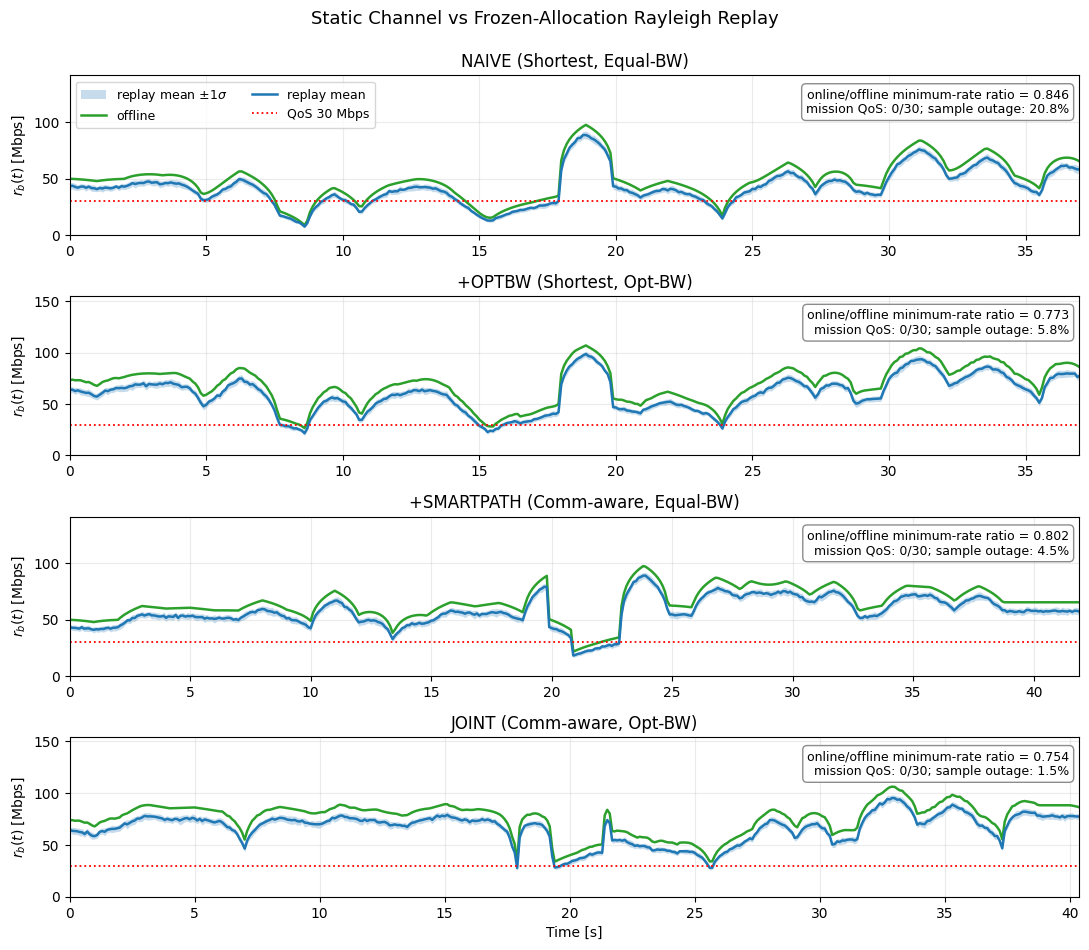

Saved: results/figures/13_offline_vs_online.png


In [8]:
# Define plot colors.
OFFLINE_COLOR = "tab:green"
ONLINE_COLOR = "tab:blue"

# Create four subplot rows.
fig, axes = plt.subplots(
    len(SCHEME_ORDER),
    1,
    figsize=(11, 9.5),
)


# =========================================================
# Plot each scheme.
# =========================================================
for ax, scheme in zip(axes, SCHEME_ORDER):
    result = RESULTS[scheme]   # offline
    online = ONLINE[scheme]    # online

    time_s = result["time_s"]   # time axis
    offline_trace = result["min_rate_bps"] / 1e6
    online_mean = online["mean_trace"] / 1e6
    online_std = online["std_trace"] / 1e6

    lower = np.maximum(online_mean - online_std, 0.0)
    upper = online_mean + online_std

    ax.fill_between(
        time_s,
        lower,
        upper,
        color=ONLINE_COLOR,
        alpha=0.25,
        linewidth=0,
        label=r"replay mean $\pm1\sigma$",
    )
    ax.plot(
        time_s,
        offline_trace,
        color=OFFLINE_COLOR,
        linewidth=1.8,
        label="offline",
    )
    ax.plot(
        time_s,
        online_mean,
        color=ONLINE_COLOR,
        linewidth=1.8,
        label="replay mean",
    )

    ax.axhline(R_QOS_REQUIRED_BPS / 1e6, color="red", linestyle=":", linewidth=1.3,
               label=f"QoS {R_QOS_REQUIRED_BPS / 1e6:g} Mbps")
    path_kind, bw_kind = SCHEME_INFO[scheme]
    ax.set(
        xlim=(0, time_s[-1]),
        ylim=(0, max(offline_trace.max(), upper.max(), R_QOS_REQUIRED_BPS / 1e6) * 1.45),
        ylabel=r"$r_b(t)$ [Mbps]",
        title=f"{scheme} ({path_kind}, {bw_kind}-BW)",
    )
    ax.grid(alpha=0.25)

    ax.text(
        0.99,
        0.92,
        f"online/offline minimum-rate ratio = {online['ratio']:.3f}\n"
        f"mission QoS: {online['qos_met'].sum()}/{N_REALIZATIONS}; "
        f"sample outage: {online['sample_outage_fraction'].mean():.1%}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9,
        bbox={
            "facecolor": "white",
            "edgecolor": "gray",
            "alpha": 0.9,
            "boxstyle": "round,pad=0.35",
        },
    )

axes[0].legend(loc="upper left", ncol=2, fontsize=9)
axes[-1].set_xlabel("Time [s]")

fig.suptitle(
    "Static Channel vs Frozen-Allocation Rayleigh Replay",
    fontsize=13,
    y=0.995,
)
fig.tight_layout()

ROBUSTNESS_PATH = FIGURES_DIR / "13_offline_vs_online.png"
fig.savefig(ROBUSTNESS_PATH, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", ROBUSTNESS_PATH.relative_to(project_config.PROJECT_DIR))

## 6. Interpret the Robustness Metrics

A smaller online/offline minimum-rate ratio indicates a larger relative loss
for that scheme in these trials. Compare absolute rates and QoS pass counts
as well: a scheme can have a smaller ratio while retaining a higher rate.
Different mission lengths and unpaired random draws limit causal comparisons.
Offline QoS feasibility does not imply QoS under this additional fading model.


In [9]:
print("[Online / offline minimum-rate ratios]")
for scheme in SCHEME_ORDER:
    online = ONLINE[scheme]
    ratio_text = f"{online['ratio']:.3f}" if np.isfinite(online["ratio"]) else "undefined (offline minimum is zero)"
    print(f"{scheme:<12}: {ratio_text}; mean online minimum = "
          f"{online['r_min_online'].mean()/1e6:.2f} Mbps; "
          f"mission QoS = {online['qos_met'].sum()}/{N_REALIZATIONS}")

naive_ratio, joint_ratio = ONLINE["NAIVE"]["ratio"], ONLINE["JOINT"]["ratio"]
if np.isfinite(naive_ratio) and np.isfinite(joint_ratio):
    relation = "larger" if joint_ratio < naive_ratio else "no larger"
    print(f"\nJOINT has a {relation} relative minimum-rate loss than NAIVE in these trials.")
print("Compare the absolute rates and mission QoS counts before ranking robustness.")
print("These finite, independent-fading trials do not establish a general reliability guarantee.")


[Online / offline minimum-rate ratios]
NAIVE       : 0.846; mean online minimum = 7.31 Mbps; mission QoS = 0/30
+OPTBW      : 0.773; mean online minimum = 20.57 Mbps; mission QoS = 0/30
+SMARTPATH  : 0.802; mean online minimum = 17.36 Mbps; mission QoS = 0/30
JOINT       : 0.754; mean online minimum = 25.27 Mbps; mission QoS = 0/30

JOINT has a larger relative minimum-rate loss than NAIVE in these trials.
Compare the absolute rates and mission QoS counts before ranking robustness.
These finite, independent-fading trials do not establish a general reliability guarantee.


## 7. Save Replay Results
Save trial-level bottleneck traces, mission minima, QoS flags, and settings for inspection without rerunning the random simulation.


In [10]:
ROBUSTNESS_RESULTS_PATH = DATA_DIR / "robustness_results.npz"
replay_data = {
    "random_seed": RANDOM_SEED,
    "n_realizations": N_REALIZATIONS,
    "n_sc": N_SC,
    "df_hz": DF_HZ,
    "r_qos_required_bps": R_QOS_REQUIRED_BPS,
}
for scheme, prefix in SCHEME_PREFIXES.items():
    replay_data[f"{prefix}_time_s"] = RESULTS[scheme]["time_s"]
    replay_data[f"{prefix}_offline_r_min_bps"] = RESULTS[scheme]["r_min_bps"]
    for key, value in ONLINE[scheme].items():
        replay_data[f"{prefix}_{key}"] = value
np.savez_compressed(ROBUSTNESS_RESULTS_PATH, **replay_data)
print("Saved:", ROBUSTNESS_RESULTS_PATH.relative_to(project_config.PROJECT_DIR))


Saved: results/data/robustness_results.npz
